<center><h1>Tang_Xiaoyun_HW6</h1></center>

Name: Xiaoyun Tang
<br>
Github Username: yuanjiujiu099-creator
<br>
USC ID: 3843547131

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer

from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

### (a) Download the APS Failure data

The compressed CSV files are in the `data` folder. The code works from the repository root or its `notebook` folder. I skip the first 20 license lines and read `na` as a missing value.

In [2]:
from pathlib import Path

data_dir = Path('data')
if not (data_dir / 'aps_failure_training_set.csv.gz').is_file():
    data_dir = Path('../data')

train = pd.read_csv(data_dir / 'aps_failure_training_set.csv.gz', skiprows=20, na_values='na')
test = pd.read_csv(data_dir / 'aps_failure_test_set.csv.gz', skiprows=20, na_values='na')

print('Training set shape:', train.shape)
print('Test set shape:', test.shape)
train.iloc[:5, :6]

Training set shape: (60000, 171)
Test set shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common methods include deleting rows or columns, filling with a constant, mean, median, or mode, and predicting missing values with KNN or regression. Iterative imputation repeats prediction and filling. I use the median because extreme values affect it less than the mean. Deleting incomplete rows would remove 59,409 of 60,000 training rows. Following the homework footnote, I fill the training and test sets with their own column medians. For cross-validation in (e) and (f), medians are learned inside each training fold.

In [3]:
# split features and labels (pos = 1, neg = 0)
X_train = train.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int)
X_test = test.drop(columns='class')
y_test = (test['class'] == 'pos').astype(int)

print('Number of training rows with at least one missing value:', X_train.isna().any(axis=1).sum())
print('Percent of all training values that are missing: %.2f%%' % (100 * X_train.isna().mean().mean()))
print()
print('Top 5 features with the most missing values (percent):')
print((100 * X_train.isna().mean()).sort_values(ascending=False).head(5).round(2))

Number of training rows with at least one missing value: 59409
Percent of all training values that are missing: 8.33%

Top 5 features with the most missing values (percent):
br_000    82.11
bq_000    81.20
bp_000    79.57
bo_000    77.22
ab_000    77.22
dtype: float64


In [4]:
# keep a copy of the training features WITH missing values (used for cross-validation in (e) and (f))
X_train_raw = X_train.copy()

# median imputation: training set uses training medians, test set uses test medians
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())

print('Missing values left in training set:', X_train.isna().sum().sum())
print('Missing values left in test set:', X_test.isna().sum().sum())

Missing values left in training set: 0
Missing values left in test set: 0


#### (ii) Calculate the coefficient of variation

The coefficient of variation is $CV = \frac{s}{m}$, where $s$ is the sample standard deviation and $m$ is the sample mean. I find it for all 170 features using the training set after filling the missing values.

In [5]:
s = X_train.std()      # sample standard deviation (ddof = 1)
m = X_train.mean()     # sample mean
cv = s / m

cv_table = pd.DataFrame({'CV': cv}).sort_values('CV', ascending=False)
# Display only the 13 features with the highest CV; cv_table keeps all 170 features.
cv_table.head(13)

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


The feature `cd_000` has the same value in every row, so its standard deviation is 0 and its CV is also 0.

#### (iii) Plot a correlation matrix

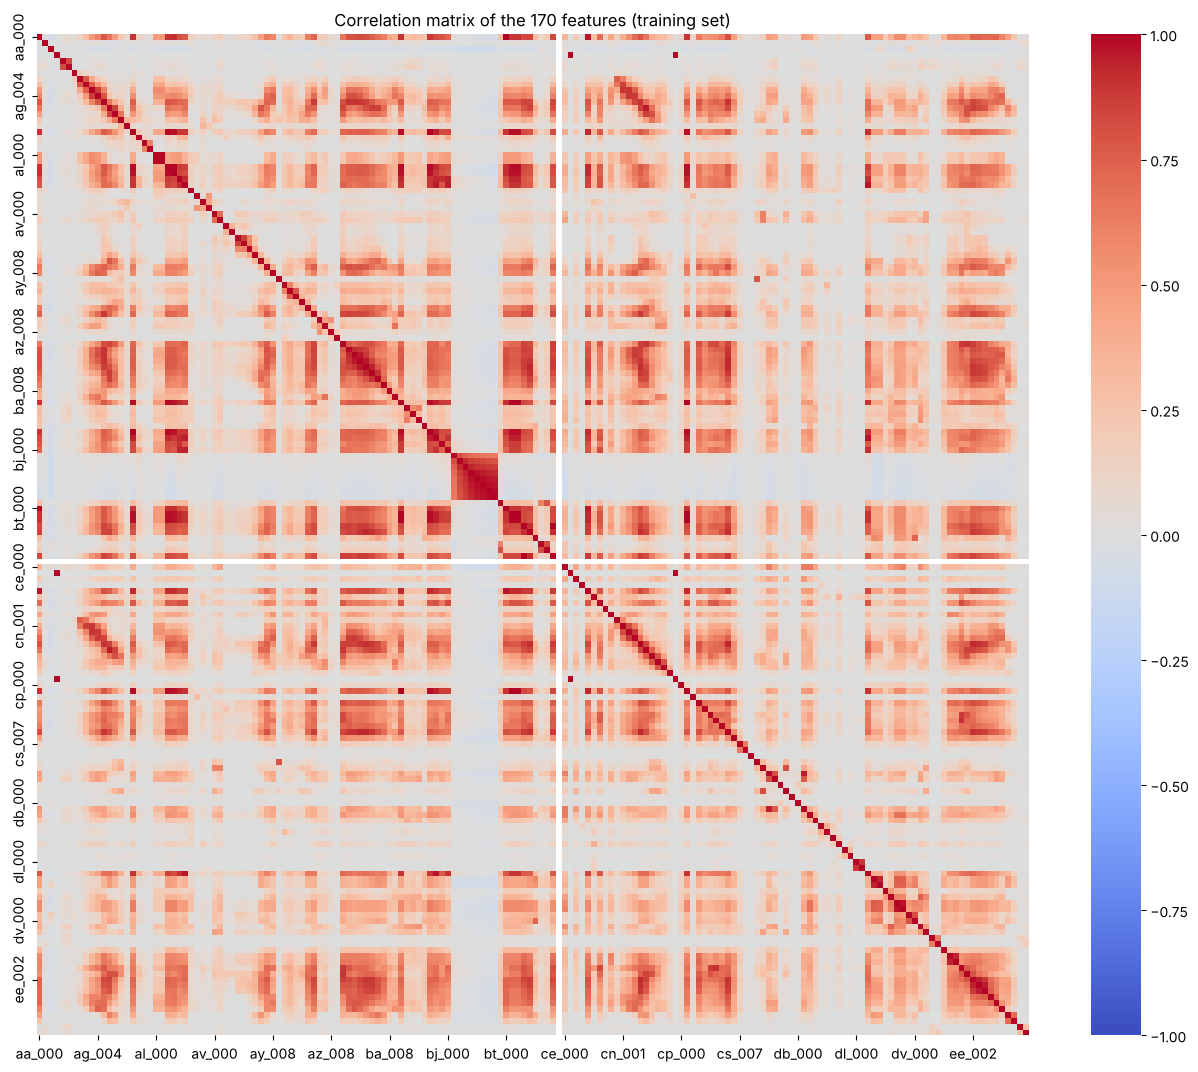

In [6]:
corr = X_train.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=10, yticklabels=10)
plt.title('Correlation matrix of the 170 features (training set)')
plt.show()

In this plot, red means two features go up together and blue means one goes up while the other goes down. There are many red blocks, so many features are strongly related to each other. This happens a lot for features from the same group, like `ag_000` to `ag_009`, `cs_000` to `cs_009`, and `ee_000` to `ee_009`. Very few pairs are blue. The one empty white row and column is `cd_000`, because it never changes, so we cannot compute its correlation.

#### (iv) Make scatter plots and box plots

In [7]:
k = int(np.floor(np.sqrt(170)))
top_features = cv_table.index[:k].tolist()
print('k =', k)
print('Features with the highest CV:', top_features)

k = 13
Features with the highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


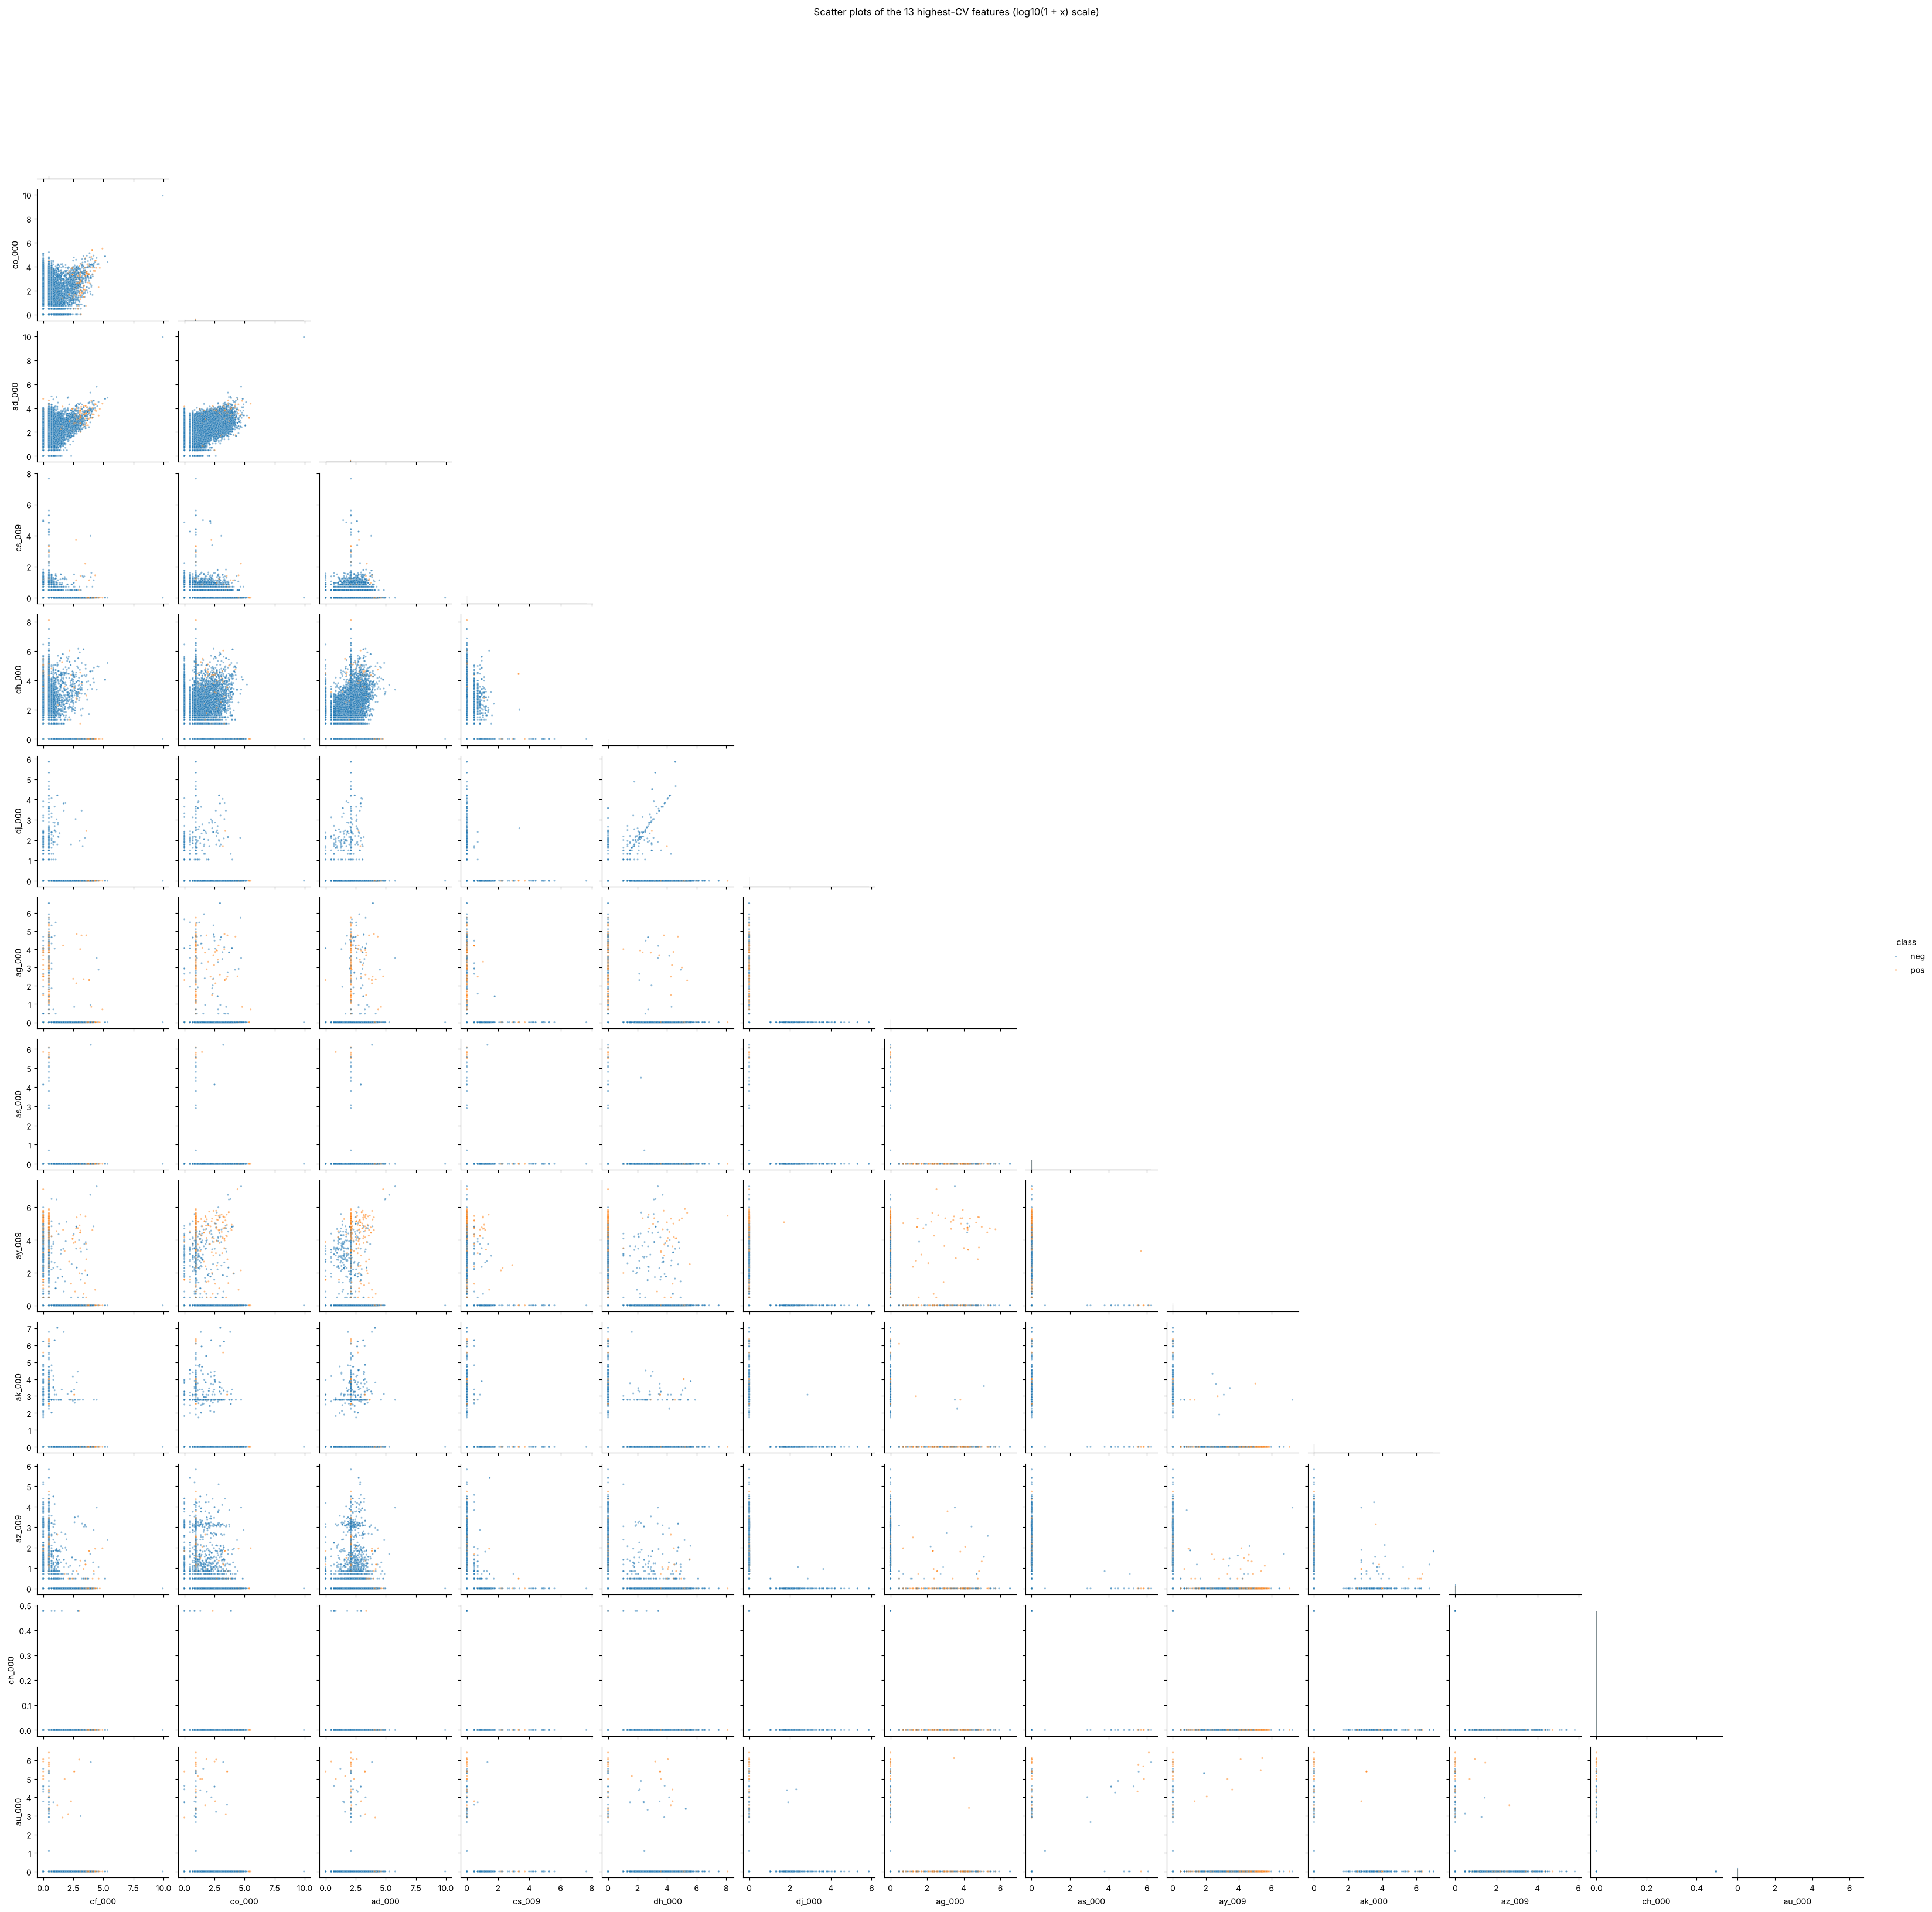

In [8]:
# The raw values have a few huge outliers (up to about 8.6e9) and most values are 0,
# so on the raw scale all points are squashed into one corner.
# Only for viewing, I plot log10(1 + x). This keeps 0 at 0 and does not change the order of the values.
log_df = np.log10(X_train[top_features] + 1)
log_df['class'] = train['class']

# scatter plots (pairwise) for the 13 features, colored by class
sns.pairplot(log_df, hue='class', hue_order=['neg', 'pos'], corner=True,
             diag_kind='hist', diag_kws={'common_norm': False, 'stat': 'density'},
             plot_kws={'s': 5, 'alpha': 0.5})
plt.suptitle('Scatter plots of the 13 highest-CV features (log10(1 + x) scale)', y=1.01)
plt.show()

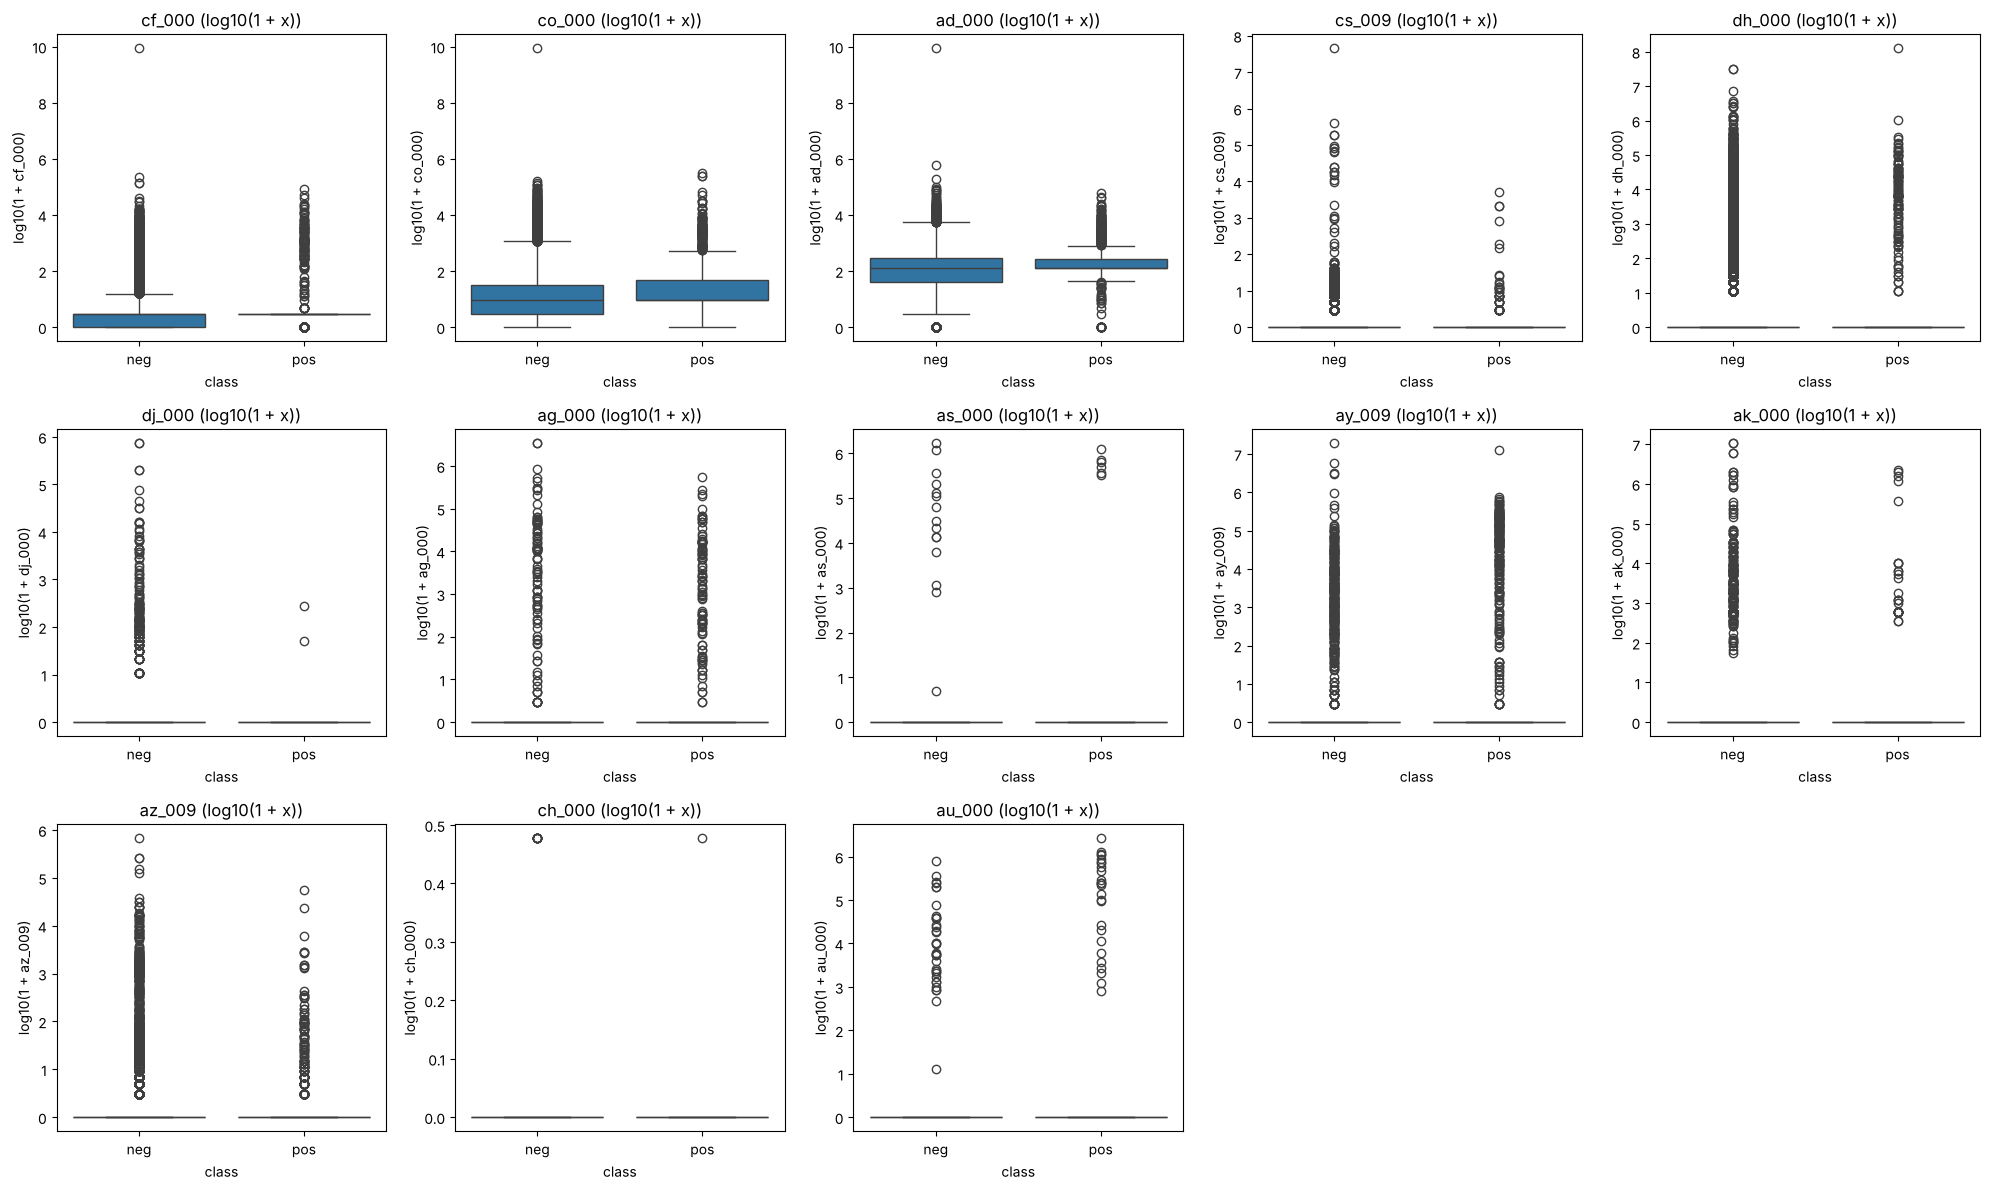

In [9]:
# Box plots use log10(1 + x) for readability; model inputs stay on the original scale.
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()
for i, f in enumerate(top_features):
    sns.boxplot(x='class', y=f, data=log_df, order=['neg', 'pos'], ax=axes[i])
    axes[i].set_title(f + ' (log10(1 + x))')
    axes[i].set_ylabel('log10(1 + ' + f + ')')
for j in range(len(top_features), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

The plots alone cannot establish which features are significant. A few extreme values make the raw scale hard to read, so both scatter plots and box plots use $\log_{10}(1+x)$ for viewing only. A high CV means large relative variation, not strong predictive value. The two classes overlap in the scatter plots, and their medians are equal for all 13 features. Median imputation also affects these distributions. The 59:1 class imbalance can hide positive points. A fitted model or an appropriate statistical test is needed to assess which features are useful.

#### (v) Is this data set imbalanced?

In [10]:
print('Training set:')
print(train['class'].value_counts())
print()
print('Test set:')
print(test['class'].value_counts())
print()
print('Percent of positive data in training set: %.2f%%' % (100 * y_train.mean()))

Training set:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test set:
class
neg    15625
pos      375
Name: count, dtype: int64

Percent of positive data in training set: 1.67%


Yes. The training set has 59,000 negative and 1,000 positive points: only 1.67% are positive. The test set has 15,625 negative and 375 positive points. Always predicting negative gives 98.33% training accuracy, so accuracy alone is misleading. I also compare confusion matrices, ROC curves, and AUC.

### (c) Train a random forest

First I write two small helper functions so I can make the same report for every model. The function `report` prints the confusion matrix, the misclassification rate, and the AUC, and the function `plot_roc` draws the ROC curves for the training set and the test set.

In [11]:
def report(model, X, y, name):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    cm = confusion_matrix(y, pred)
    cm_df = pd.DataFrame(cm, index=['True neg', 'True pos'], columns=['Pred neg', 'Pred pos'])
    error = 1 - accuracy_score(y, pred)
    auc = roc_auc_score(y, prob)
    print('=====', name, '=====')
    print(cm_df)
    print('Misclassification rate: %.4f' % error)
    print('AUC: %.4f' % auc)
    print()
    return error, auc, cm

def plot_roc(model, X_tr, y_tr, X_te, y_te, title):
    plt.figure(figsize=(6, 6))
    for X, y, label in [(X_tr, y_tr, 'Train'), (X_te, y_te, 'Test')]:
        prob = model.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, prob)
        auc = roc_auc_score(y, prob)
        plt.plot(fpr, tpr, label='%s (AUC = %.4f)' % (label, auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend()
    plt.show()

===== Random Forest - Training set =====
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999
Misclassification rate: 0.0000
AUC: 1.0000



===== Random Forest - Test set =====
          Pred neg  Pred pos
True neg     15610        15
True pos       106       269
Misclassification rate: 0.0076
AUC: 0.9928



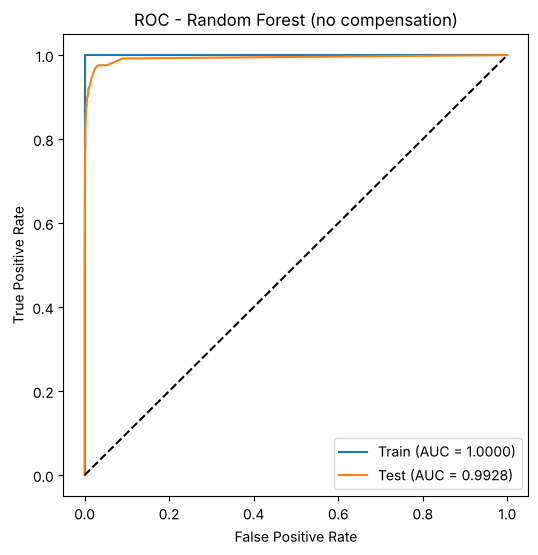

In [12]:
rf = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_train_err, rf_train_auc, _ = report(rf, X_train, y_train, 'Random Forest - Training set')
rf_test_err, rf_test_auc, rf_test_cm = report(rf, X_test, y_test, 'Random Forest - Test set')
plot_roc(rf, X_train, y_train, X_test, y_test, 'ROC - Random Forest (no compensation)')

In [13]:
rf_oob_err = 1 - rf.oob_score_
print('OOB error estimate: %.4f' % rf_oob_err)
print('Test error:         %.4f' % rf_test_err)

OOB error estimate: 0.0062
Test error:         0.0076


The forest makes only one training mistake; its error rounds to 0.0000. Test error is 0.0076 and test AUC is 0.9928. OOB error is 0.0062, slightly below test error. OOB predictions use trees that did not train on the given point. Despite the low overall error, the model misses 106 of 375 failures and raises 15 false alarms. It detects about 72% of failures, so the rare class remains difficult.

### (d) Research class imbalance in random forest

Class imbalance can be handled with class weights, under-sampling, over-sampling such as SMOTE, or a lower decision cutoff. I use `BalancedRandomForestClassifier`, which draws equally sized samples from the two classes for each tree. This gives rare positive points more influence than in an ordinary forest. I use sampling with replacement, bootstrap sampling, 100 trees, and random seed 42. I compare its errors, AUC, and failure-detection cost with the forest in (c).

===== Balanced Random Forest - Training set =====
          Pred neg  Pred pos
True neg     56100      2900
True pos        13       987
Misclassification rate: 0.0485
AUC: 0.9956

===== Balanced Random Forest - Test set =====
          Pred neg  Pred pos
True neg     14888       737
True pos         8       367
Misclassification rate: 0.0466
AUC: 0.9917



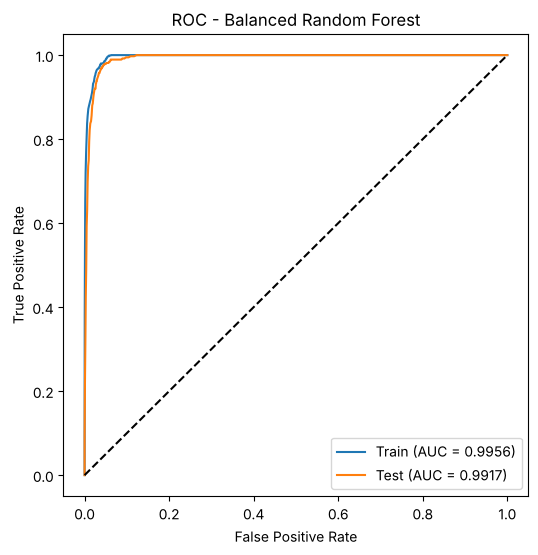

In [14]:
brf = BalancedRandomForestClassifier(n_estimators=100, sampling_strategy='all', replacement=True,
                                     bootstrap=True, oob_score=True, random_state=42, n_jobs=-1)
brf.fit(X_train, y_train)

brf_train_err, brf_train_auc, _ = report(brf, X_train, y_train, 'Balanced Random Forest - Training set')
brf_test_err, brf_test_auc, brf_test_cm = report(brf, X_test, y_test, 'Balanced Random Forest - Test set')
plot_roc(brf, X_train, y_train, X_test, y_test, 'ROC - Balanced Random Forest')

In [15]:
brf_oob_err = 1 - brf.oob_score_
print('OOB error estimate: %.4f' % brf_oob_err)
print('Test error:         %.4f' % brf_test_err)

OOB error estimate: 0.0294
Test error:         0.0466


The data description gives a cost for each kind of mistake. A false positive (checking a truck for no reason) costs 10, and a false negative (missing a real failure) costs 500, so missing a failure is 50 times worse than a false alarm. I use this cost to compare the two forests on the test set.

In [16]:
def total_cost(cm):
    fp = cm[0, 1]
    fn = cm[1, 0]
    return 10 * fp + 500 * fn

compare_rf = pd.DataFrame({
    'Model': ['Random Forest (c)', 'Balanced Random Forest (d)'],
    'Test error': [rf_test_err, brf_test_err],
    'Test AUC': [rf_test_auc, brf_test_auc],
    'False positives': [rf_test_cm[0, 1], brf_test_cm[0, 1]],
    'False negatives': [rf_test_cm[1, 0], brf_test_cm[1, 0]],
    'OOB error': [rf_oob_err, brf_oob_err],
    'Cost (10*FP + 500*FN)': [total_cost(rf_test_cm), total_cost(brf_test_cm)]
})
compare_rf

,Model,Test error,Test AUC,False positives,False negatives,OOB error,Cost (10*FP + 500*FN)
0,Random Forest (c),0.007563,0.992756,15,106,0.006167,53150
1,Balanced Random Forest (d),0.046562,0.991652,737,8,0.029417,11370


The balanced forest detects 367 of 375 failures (about 98%). Compared with (c), missed failures drop from 106 to 8, while false alarms rise from 15 to 737. Test error rises to 0.0466, and AUC changes little (0.9928 to 0.9917). OOB error is 0.0294, so it underestimates the observed test error. With a cost of 10 per false positive and 500 per false negative, total test cost falls from 53,150 to 11,370. The balanced forest therefore performs better under this cost measure.

### (e) XGBoost and Model Trees

I use `XGBClassifier` with logistic loss (`binary:logistic`) and tune `reg_alpha`, the L1 penalty on leaf weights. Larger penalties can set more leaf weights to zero. This is boosted trees with logistic loss; it does not fit a separate logistic regression inside each node. I use XGBoost as allowed by the homework.

I try $\alpha \in \{0, 0.01, 0.1, 1, 10, 100\}$ using stratified 5-fold CV. The pipeline starts from `X_train_raw` and learns median imputation inside each training fold. I select the highest CV AUC and also record CV error. Class imbalance is not compensated in this part.

In [17]:
alphas = [0, 0.01, 0.1, 1, 10, 100]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('xgb', XGBClassifier(objective='binary:logistic', n_estimators=100, tree_method='hist',
                          random_state=42, n_jobs=-1))
])

xgb_grid = GridSearchCV(xgb_pipe, param_grid={'xgb__reg_alpha': alphas}, cv=skf,
                        scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'}, refit='auc')
xgb_grid.fit(X_train_raw, y_train)

xgb_cv_table = pd.DataFrame({
    'alpha': alphas,
    'CV AUC': xgb_grid.cv_results_['mean_test_auc'],
    'CV error': 1 - xgb_grid.cv_results_['mean_test_accuracy']
})
print(xgb_cv_table)
print()
best_alpha = xgb_grid.best_params_['xgb__reg_alpha']
print('Best alpha:', best_alpha)

    alpha    CV AUC  CV error
0    0.00  0.984673  0.006450
1    0.01  0.984025  0.006333
2    0.10  0.985380  0.006517
3    1.00  0.985759  0.006417
4   10.00  0.978537  0.008533
5  100.00  0.981298  0.011583

Best alpha: 1


===== XGBoost - Training set =====
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999
Misclassification rate: 0.0000
AUC: 1.0000

===== XGBoost - Test set =====
          Pred neg  Pred pos
True neg     15601        24
True pos        90       285
Misclassification rate: 0.0071
AUC: 0.9930



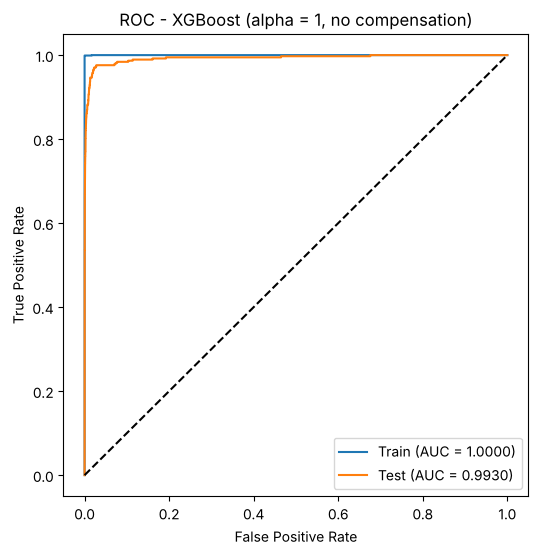

5-fold CV error estimate: 0.0064
Test error:               0.0071


In [18]:
# refit on the whole training set with the best alpha
# (the test set was already filled with its own medians, so the imputer does nothing to it)
xgb_best = xgb_grid.best_estimator_
best_idx = xgb_grid.best_index_
xgb_cv_err = 1 - xgb_grid.cv_results_['mean_test_accuracy'][best_idx]

xgb_train_err, xgb_train_auc, _ = report(xgb_best, X_train, y_train, 'XGBoost - Training set')
xgb_test_err, xgb_test_auc, xgb_test_cm = report(xgb_best, X_test, y_test, 'XGBoost - Test set')
plot_roc(xgb_best, X_train, y_train, X_test, y_test, 'ROC - XGBoost (alpha = %s, no compensation)' % best_alpha)

print('5-fold CV error estimate: %.4f' % xgb_cv_err)
print('Test error:               %.4f' % xgb_test_err)

The selected value is $\alpha=1$, with CV AUC 0.9858. CV error is 0.0064 versus test error 0.0071. Because the same CV selects the penalty and estimates error, this estimate can be optimistic. The model makes one training mistake. On the test set, AUC is 0.9930, with 90 missed failures and 24 false alarms. It misses fewer failures than the random forest in (c), but still misses 24% of positive cases.

### (f) Use SMOTE to pre-process your data

SMOTE creates synthetic positive points between a positive point and one of its five nearest positive neighbors. For the final fit, it increases the positive class from 1,000 to 59,000 points.

The wrong approach applies SMOTE before CV, allowing related original and synthetic points to enter different folds. The correct pipeline learns medians and applies SMOTE inside each training fold, then evaluates on the original validation fold. I select $\alpha$ using CV AUC and refit this pipeline on the full training set. SMOTE is never applied to the test set.

In [19]:
smote_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(objective='binary:logistic', n_estimators=100, tree_method='hist',
                          random_state=42, n_jobs=-1))
])

# right way: imputation and SMOTE are done inside each CV fold, only on the training part
smote_grid = GridSearchCV(smote_pipe, param_grid={'xgb__reg_alpha': alphas}, cv=skf,
                          scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'}, refit='auc')
smote_grid.fit(X_train_raw, y_train)

smote_cv_table = pd.DataFrame({
    'alpha': alphas,
    'CV AUC': smote_grid.cv_results_['mean_test_auc'],
    'CV error': 1 - smote_grid.cv_results_['mean_test_accuracy']
})
print(smote_cv_table)
print()
best_alpha_smote = smote_grid.best_params_['xgb__reg_alpha']
print('Best alpha:', best_alpha_smote)

    alpha    CV AUC  CV error
0    0.00  0.985290  0.006683
1    0.01  0.985704  0.006317
2    0.10  0.986874  0.006517
3    1.00  0.987012  0.006650
4   10.00  0.985911  0.007800
5  100.00  0.984354  0.017300

Best alpha: 1


Training set after SMOTE: (118000, 170)
class
neg    59000
pos    59000
Name: count, dtype: int64



===== SMOTE + XGBoost - Training set =====
          Pred neg  Pred pos
True neg     59000         0
True pos         1       999
Misclassification rate: 0.0000
AUC: 1.0000

===== SMOTE + XGBoost - Test set =====
          Pred neg  Pred pos
True neg     15554        71
True pos        56       319
Misclassification rate: 0.0079
AUC: 0.9945



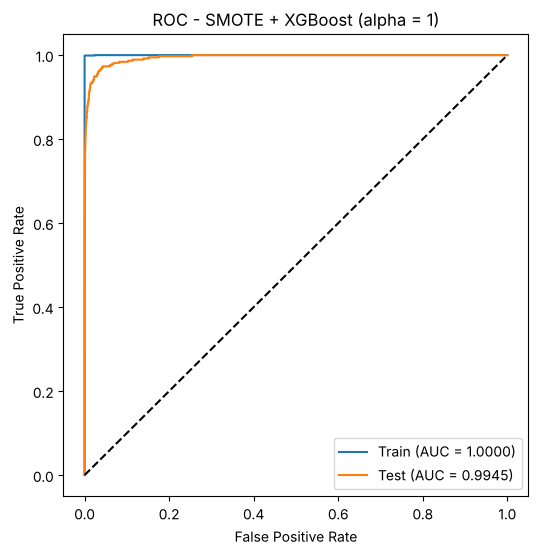

5-fold CV error estimate (right way): 0.0066
Test error:                           0.0079


In [20]:
# the best pipeline was refit on the whole training set: impute, SMOTE on all 60,000 rows, then XGBoost
smote_best = smote_grid.best_estimator_
best_idx = smote_grid.best_index_
smote_cv_err = 1 - smote_grid.cv_results_['mean_test_accuracy'][best_idx]

X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print('Training set after SMOTE:', X_sm.shape)
print(pd.Series(y_sm).value_counts().rename({0: 'neg', 1: 'pos'}))
print()

# training metrics are computed on the original training data (no synthetic points)
sm_train_err, sm_train_auc, _ = report(smote_best, X_train, y_train, 'SMOTE + XGBoost - Training set')
sm_test_err, sm_test_auc, sm_test_cm = report(smote_best, X_test, y_test, 'SMOTE + XGBoost - Test set')
plot_roc(smote_best, X_train, y_train, X_test, y_test, 'ROC - SMOTE + XGBoost (alpha = %s)' % best_alpha_smote)

print('5-fold CV error estimate (right way): %.4f' % smote_cv_err)
print('Test error:                           %.4f' % sm_test_err)

Just to compare, here is the wrong way, where SMOTE is run on the whole training set first and then 5-fold CV is done on the over-sampled data.

In [21]:
wrong_model = XGBClassifier(objective='binary:logistic', n_estimators=100, tree_method='hist',
                            reg_alpha=best_alpha_smote, random_state=42, n_jobs=-1)
wrong_acc = cross_val_score(wrong_model, X_sm, y_sm, cv=skf, scoring='accuracy')
print('CV error, wrong way (SMOTE before CV): %.4f' % (1 - wrong_acc.mean()))
print('CV error, right way (SMOTE inside CV): %.4f' % smote_cv_err)
print('Test error:                            %.4f' % sm_test_err)

CV error, wrong way (SMOTE before CV): 0.0024
CV error, right way (SMOTE inside CV): 0.0066
Test error:                            0.0079


**Comparison of the uncompensated case and the SMOTE case**

In [22]:
compare_xgb = pd.DataFrame({
    'Model': ['XGBoost, no compensation (e)', 'SMOTE + XGBoost (f)'],
    'Best alpha': [best_alpha, best_alpha_smote],
    'CV error': [xgb_cv_err, smote_cv_err],
    'Test error': [xgb_test_err, sm_test_err],
    'Train AUC': [xgb_train_auc, sm_train_auc],
    'Test AUC': [xgb_test_auc, sm_test_auc],
    'False positives': [xgb_test_cm[0, 1], sm_test_cm[0, 1]],
    'False negatives': [xgb_test_cm[1, 0], sm_test_cm[1, 0]],
    'Cost (10*FP + 500*FN)': [total_cost(xgb_test_cm), total_cost(sm_test_cm)]
})
compare_xgb

,Model,Best alpha,CV error,Test error,Train AUC,Test AUC,False positives,False negatives,Cost (10*FP + 500*FN)
0,"XGBoost, no compensation (e)",1,0.006417,0.007125,0.999983,0.992959,24,90,45240
1,SMOTE + XGBoost (f),1,0.006650,0.007938,0.999976,0.994463,71,56,28710


The correct CV error is 0.0066, compared with test error 0.0079. Applying SMOTE before CV gives 0.0024, an optimistic estimate affected by leakage; it also evaluates a resampled class distribution. Both XGBoost models select $\alpha=1$.

With SMOTE, missed failures fall from 90 to 56, while false alarms rise from 24 to 71. Test error changes from 0.0071 to 0.0079, and AUC from 0.9930 to 0.9945. Under the stated costs, total cost falls from 45,240 to 28,710. The main improvement is finding more failures, with more false alarms. The balanced forest in (d) catches still more failures but produces many more false alarms.

## 2. ISLR 6.6.3

Here we fit the model by making $\sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2$ as small as possible while keeping $\sum_{j=1}^{p}|\beta_j|\le s$, which is the lasso. When $s=0$, all slopes are 0 and the model is very simple. As $s$ gets bigger, the limit gets looser and the model becomes more flexible, and when $s$ is big enough we just get the least squares fit.

**(a)** The answer is (iv), steadily decrease. A bigger $s$ lets the slopes grow, so the model can fit the training data better and better. A bigger $s$ only gives more choices, so the training RSS can never go up, and it keeps going down until it reaches the least squares RSS.

**(b)** The answer is (ii), decrease at first and then increase in a U shape. At $s=0$ the model is too simple, so the test RSS is high. As $s$ grows, the model starts to catch the real pattern and the test RSS drops, but after some point the model becomes too flexible and starts fitting the noise in the training data, so the test RSS goes back up.

**(c)** The answer is (iii), steadily increase. At $s=0$ all slopes are 0, so the model just predicts the sample mean $\hat\beta_0=\bar y$. This guess can still change a little from one training set to another, so the variance is low here but not zero. As $s$ grows, the model becomes more flexible and depends more on the exact training data, so the variance keeps going up.

**(d)** The answer is (iv), steadily decrease. At $s=0$ the model is too simple, so the bias is large. As $s$ grows, the model becomes more flexible and can get closer to the true pattern, so the bias keeps going down.

**(e)** The answer is (v), remain constant. The irreducible error comes from the noise $\epsilon$ in the data, not from the model, so changing $s$ does not change it.

## 3. ISLR 6.6.5

We have $n=2$, $p=2$, $x_{11}=x_{12}$, $x_{21}=x_{22}$, $y_1+y_2=0$, $x_{11}+x_{21}=0$, and $x_{12}+x_{22}=0$, so $\hat\beta_0=0$.

**(a)** Ridge regression picks $\beta_1$ and $\beta_2$ to make this as small as possible:
$$(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2)$$

**(b)** Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, I write $x_1=x_{11}=x_{12}$ and $x_2=x_{21}=x_{22}$, so the thing we minimize becomes $f(\beta_1,\beta_2)=(y_1-(\beta_1+\beta_2)x_1)^2+(y_2-(\beta_1+\beta_2)x_2)^2+\lambda(\beta_1^2+\beta_2^2)$. At the minimum, both partial derivatives are 0:
$$\frac{\partial f}{\partial\beta_1}=-2x_1\big(y_1-(\beta_1+\beta_2)x_1\big)-2x_2\big(y_2-(\beta_1+\beta_2)x_2\big)+2\lambda\beta_1=0$$
$$\frac{\partial f}{\partial\beta_2}=-2x_1\big(y_1-(\beta_1+\beta_2)x_1\big)-2x_2\big(y_2-(\beta_1+\beta_2)x_2\big)+2\lambda\beta_2=0$$
The first two terms are exactly the same in both lines, so if we subtract the second line from the first, we get $2\lambda(\beta_1-\beta_2)=0$. Since $\lambda>0$, this means $\hat\beta_1=\hat\beta_2$. Also, the ridge problem has only one minimum when $\lambda>0$, so this is the only answer.

**(c)** The lasso picks $\beta_1$ and $\beta_2$ to make this as small as possible:
$$(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|)$$

**(d)** Using the same short names, and also $x_2=-x_1$ and $y_2=-y_1$, the RSS part becomes $2\big(y_1-(\beta_1+\beta_2)x_1\big)^2$, so it only depends on the sum $c=\beta_1+\beta_2$. For the penalty, $|\beta_1|+|\beta_2|$ is always at least $|\beta_1+\beta_2|$, and the two are equal when $\beta_1$ and $\beta_2$ have the same sign (or one of them is 0). So for a fixed sum $c$, every pair with the same sign gives exactly the same value $2(y_1-cx_1)^2+\lambda|c|$. The lasso first finds the best sum $c$ by minimizing $g(c)=2(y_1-cx_1)^2+\lambda|c|$ (assuming $x_1\neq0$), and setting the derivative to 0 gives
$$c=\text{sign}\!\left(\frac{y_1}{x_1}\right)\max\!\left(\left|\frac{y_1}{x_1}\right|-\frac{\lambda}{4x_1^2},\ 0\right)$$
If $\lambda < 4|x_1y_1|$, then $c\neq0$, and every point on the line $\hat\beta_1+\hat\beta_2=c$ with $\hat\beta_1\ge0$ and $\hat\beta_2\ge0$ (or both $\le0$ if $c<0$) gives the same smallest value, so there are infinitely many lasso answers and the coefficients are not unique. If $\lambda \ge 4|x_1y_1|$, the penalty is big enough that $c=0$, and then the only answer is $\hat\beta_1=\hat\beta_2=0$. So, unlike ridge, the lasso coefficients can be non-unique, because any split of the sum $c$ between $\hat\beta_1$ and $\hat\beta_2$ with the same sign works, except in the special case $c=0$. We can also see this in a picture: the lasso limit $|\beta_1|+|\beta_2|\le s$ is a diamond, and the RSS contours are the lines $\beta_1+\beta_2=\text{constant}$, which are parallel to two edges of the diamond. So when the least squares answer is outside the diamond, the contour touches the diamond along a whole edge instead of at one corner, and every point on that edge is a lasso answer.

## 4. ISLR 8.4.5

The ten estimates of $P(\text{Class is Red}\mid X)$ are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, and 0.75, and we use 0.5 as the cutoff. With the majority vote, 6 of the 10 estimates are above 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), so 6 trees vote Red and 4 trees vote Green, and the final answer is **Red**. With the average probability, we get $\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}=\frac{4.5}{10}=0.45$, and since $0.45<0.5$, the final answer is **Green**. So the two methods give different answers here.

In [23]:
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print('Number of Red votes:', (p > 0.5).sum(), 'out of', len(p))
print('Average probability:', p.mean())

Number of Red votes: 6 out of 10
Average probability: 0.45


## 5. ISLR 9.7.3

We have seven points:

| Obs. | $X_1$ | $X_2$ | $Y$ |
|---|---|---|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a)** The top-left panel below shows the seven points.

**(b)** In the plot, the closest red and blue points come in pairs: Red (2, 2) is right above Blue (2, 1), and Red (4, 4) is right above Blue (4, 3). The gap between the two classes is the band between the line through the red points (2, 2) and (4, 4), which is $X_2 = X_1$, and the line through the blue points (2, 1) and (4, 3), which is $X_2 = X_1 - 1$. The best separating hyperplane is right in the middle of these two lines, so it goes through (2, 1.5) and (4, 3.5), and its equation is $X_2 = X_1 - 0.5$, or $0.5 - X_1 + X_2 = 0$.

**(c)** Here $\beta_0 = 0.5$, $\beta_1 = -1$, and $\beta_2 = 1$. We classify a point as Red if $0.5 - X_1 + X_2 > 0$ and as Blue if $0.5 - X_1 + X_2 < 0$. For example, point 1 at (3, 4) gives $0.5-3+4=1.5>0$, so it is Red, and point 7 at (4, 1) gives $0.5-4+1=-2.5<0$, so it is Blue. The code below checks that all 7 points are classified correctly.

**(d)** The margin is the distance from the hyperplane to the closest points. For (2, 2) it is $M=\frac{|0.5-2+2|}{\sqrt{(-1)^2+1^2}}=\frac{0.5}{\sqrt2}\approx 0.354$. In the top-right panel below, the margin is shown by the two dashed lines $X_2 = X_1$ and $X_2 = X_1-1$, and the whole band is $2M = 1/\sqrt2 \approx 0.707$ wide.

**(e)** The support vectors are the points that sit on the edge of the margin, which are point 2 (2, 2) and point 3 (4, 4) for Red, and point 5 (2, 1) and point 6 (4, 3) for Blue. They are circled in green in the top-right panel.

**(f)** Point 7 is at (4, 1), and it is not a support vector. Its distance to the hyperplane is $|0.5-4+1|/\sqrt2 = 2.5/\sqrt2 \approx 1.77$, which is much bigger than the margin of 0.354. The best hyperplane only depends on the support vectors, so if we move point 7 a little and it stays outside the margin on the Blue side, the hyperplane does not change.

**(g)** The bottom-left panel shows one example is $0.1 - X_1 + X_2 = 0$, which is the line $X_2 = X_1 - 0.1$. It still splits the two classes, because all red points give a positive value and all blue points give a negative value. But it is very close to the red points (2, 2) and (4, 4), so its margin is only $0.1/\sqrt2 \approx 0.07$, which is smaller than the best margin, so it is not the optimal hyperplane.

**(h)** In the bottom-right panel, I add a Red point at (4, 2). It sits between the two Blue points (4, 1) and (4, 3) on the same vertical line. Any straight line that puts (4, 1) and (4, 3) on the Blue side also puts every point between them on the Blue side, including (4, 2). So no hyperplane can split the two classes anymore.

Optimal rule classifies all 7 points correctly: True
Margin M = 0.3536
Non-optimal rule separates the classes: True


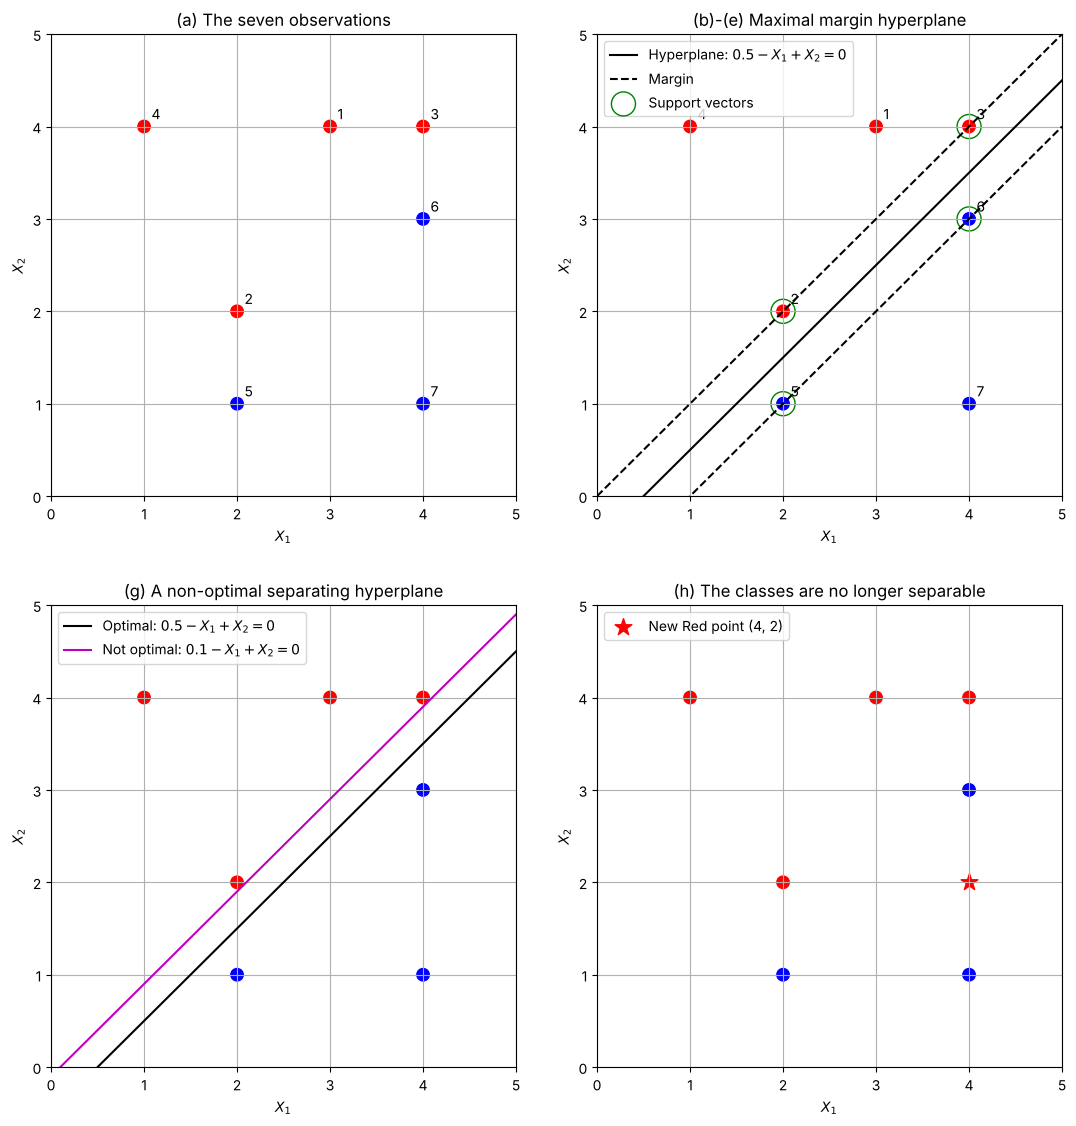

In [24]:
X1 = np.array([3, 2, 4, 1, 2, 4, 4])
X2 = np.array([4, 2, 4, 4, 1, 3, 1])
Y = np.array(['red', 'red', 'red', 'red', 'blue', 'blue', 'blue'])
xs = np.linspace(0, 5, 100)
f = 0.5 - X1 + X2
f_g = 0.1 - X1 + X2
print('Optimal rule classifies all 7 points correctly:', np.all((f > 0) == (Y == 'red')))
print('Margin M = %.4f' % (0.5 / np.sqrt(2)))
print('Non-optimal rule separates the classes:', np.all((f_g > 0) == (Y == 'red')))

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for ax in axes.flat:
    ax.scatter(X1, X2, c=Y, s=80)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='$X_1$', ylabel='$X_2$')
    ax.grid(True)
for ax in axes[0]:
    for i in range(7):
        ax.annotate(str(i + 1), (X1[i] + 0.08, X2[i] + 0.08))

axes[0, 0].set_title('(a) The seven observations')

ax = axes[0, 1]
ax.plot(xs, xs - 0.5, 'k-', label='Hyperplane: $0.5 - X_1 + X_2 = 0$')
ax.plot(xs, xs, 'k--', label='Margin')
ax.plot(xs, xs - 1, 'k--')
sv = [1, 2, 4, 5]
ax.scatter(X1[sv], X2[sv], s=300, facecolors='none', edgecolors='green', label='Support vectors')
ax.set_title('(b)-(e) Maximal margin hyperplane')
ax.legend(loc='upper left')

ax = axes[1, 0]
ax.plot(xs, xs - 0.5, 'k-', label='Optimal: $0.5 - X_1 + X_2 = 0$')
ax.plot(xs, xs - 0.1, 'm-', label='Not optimal: $0.1 - X_1 + X_2 = 0$')
ax.set_title('(g) A non-optimal separating hyperplane')
ax.legend(loc='upper left')

ax = axes[1, 1]
ax.scatter([4], [2], c='red', s=160, marker='*', label='New Red point (4, 2)')
ax.set_title('(h) The classes are no longer separable')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()